In [1]:
# Test BARRA daily WBGT data for unrealistic values
# Test over entire domain or specified region
# Output includes:
#     - scatterplot used in treasury report, as well as additional plots used to interrogate the data
#     - text files for use in other script (wbgt_BARRA_testing_single_lat_lon_Treasury.ipynb)

In [2]:
# Import modules
import numpy as np
import netCDF4 as nc
import xarray as xr
import time as time_pack
import sys, os
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
import glob


In [3]:
def print_run_time(start_timer):
    end_timer = time_pack.perf_counter()
    print('')
    print('Code run time: ' + str(np.round((end_timer - start_timer) / 60,2)) + ' minutes')
    

In [4]:
set_month = '04' # e.g. '01'
daily_freq = 'max' # 'max' = daily maximum data

apply_ocean_area_mask = 'yes' # If 'yes' - only land regions will be examined
crop_to_aust_region = 'yes' # If 'yes' - will be cropped to BARRA-C2 region


In [5]:
start_year = 1979
end_year = 2024


In [6]:
# Get filenames

# Daily data
data_location = '/g/data/eg3/cdr565/data/BARRA-R2_wbgt_test/wbgt/daily/'

if (set_month == 'all') and ('tp28' in data_location):
    fnames = glob.glob('{}wbgt*.nc'.format(data_location))
elif 'tp28' in data_location:
    fnames = glob.glob('{}wbgt*{}.nc'.format(data_location,set_month))
elif (set_month == 'all') and ('eg3' in data_location):
    fnames = glob.glob('{}wbgt*_day_{}.nc'.format(data_location,daily_freq))
elif 'eg3' in data_location:
    fnames = glob.glob('{}wbgt*{}_day_{}.nc'.format(data_location,set_month,daily_freq))
fnames.sort()

assert len(fnames) == end_year - start_year + 1

print(fnames[0])
print(fnames[-1])


/g/data/eg3/cdr565/data/BARRA-R2_wbgt_test/wbgt/daily/wbgt_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_197904-197904_day_max.nc
/g/data/eg3/cdr565/data/BARRA-R2_wbgt_test/wbgt/daily/wbgt_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_202404-202404_day_max.nc


In [7]:
if crop_to_aust_region == 'yes': # AUST region
    geospatial_lat_min = -45.76
    geospatial_lat_max = -4.95
    geospatial_lon_min = 107.95
    geospatial_lon_max = 159.98


In [8]:
# This function allows for reading in part of an nc file
from functools import partial
def _preprocess(x, lon_bnds, lat_bnds):
    try:
        return x.sel(lon=slice(*lon_bnds), lat=slice(*lat_bnds))
    except:
        return x.sel(longitude=slice(*lon_bnds), latitude=slice(*lat_bnds))

lon_bnds, lat_bnds = (geospatial_lon_min, geospatial_lon_max), (geospatial_lat_min, geospatial_lat_max)
partial_func = partial(_preprocess, lon_bnds=lon_bnds, lat_bnds=lat_bnds)


In [9]:
# Open netcdf files
if (crop_to_aust_region == 'yes'):
    ds = xr.open_mfdataset(fnames,parallel=True,compat='no_conflicts',preprocess=partial_func)
else:
    ds = xr.open_mfdataset(fnames,parallel=True,compat='no_conflicts')


In [10]:
# If wrong number of entries read in, stop script - try running script again as sometimes it works the second time
if set_month in ['01', '03', '05', '07', '08', '10', '12']:
    set_days = (end_year - start_year + 1) * 31
elif set_month in ['04', '06', '09', '11']:
    set_days = (end_year - start_year + 1) * 30
elif set_month == '02':
    assert start_year == 1979
    assert end_year == 2024
    set_days = 1300

if len(ds.time) != set_days:
    sys.exit()
    

In [11]:
# T data

# Daily data
data_location_T = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/day/tas' + daily_freq + '/latest/'

fnames_T = glob.glob('{}tas{}*_day_*{}.nc'.format(data_location_T,daily_freq,set_month))
fnames_T.sort()

t_var_name = 'tas' + daily_freq

for i in np.arange(len(fnames_T)): # Remove 2025 filenames from list
    if ('2025' + set_month + '.nc' in fnames_T[i]) and (i+1 == len(fnames_T)):
        fnames_T = fnames_T[0:-1]
        
assert len(fnames_T) == end_year - start_year + 1

print(fnames_T[0])
print(fnames_T[-1])


/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/day/tasmax/latest/tasmax_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_day_197904-197904.nc
/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/day/tasmax/latest/tasmax_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_day_202404-202404.nc


In [12]:
# Open dry-bulb temperature data

if (crop_to_aust_region == 'yes'):
    ds_t = xr.open_mfdataset(fnames_T,parallel=True,coords='minimal',compat='no_conflicts',preprocess=partial_func)
else:
    ds_t = xr.open_mfdataset(fnames_T,parallel=True,coords='minimal',compat='no_conflicts')


In [13]:
# Make sure datasets are the same length
assert len(ds.time) == len(ds_t.time)


In [14]:
# Import land area fraction data
laf_dir = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/fx/sftlf/latest/'
laf_fnames = glob.glob('{}*.nc'.format(laf_dir))
print(laf_fnames)
assert len(laf_fnames) == 1

if (crop_to_aust_region == 'yes'):
    laf_ds = xr.open_mfdataset(laf_fnames[0],preprocess=partial_func)
else:
    laf_ds = xr.open_dataset(laf_fnames[0])


['/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/fx/sftlf/latest/sftlf_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1.nc']


In [15]:
# Create land and ocean area mask

# Make laf 1-NaN array
land_regions_100pc = np.array(laf_ds.sftlf.data).copy()
land_regions_100pc[np.where(land_regions_100pc < 100)] = np.nan
land_regions_100pc[np.where(land_regions_100pc == 100)] = 1.0

land_regions_1pc_plus = np.array(laf_ds.sftlf.data).copy()
land_regions_1pc_plus[np.where(land_regions_1pc_plus == 0)] = np.nan
land_regions_1pc_plus[np.where(land_regions_1pc_plus > 0)] = 1.0

land_regions_50pc = np.array(laf_ds.sftlf.data).copy()
land_regions_50pc[np.where(land_regions_50pc < 50.)] = np.nan
land_regions_50pc[np.where(land_regions_50pc >= 50.)] = 1.0

ocean_regions_1pc_plus = np.array(laf_ds.sftlf.data).copy()
ocean_regions_1pc_plus[np.where(ocean_regions_1pc_plus == 100)] = np.nan
ocean_regions_1pc_plus[np.where(ocean_regions_1pc_plus < 100)] = 1.0

ocean_regions_100pc = np.array(laf_ds.sftlf.data).copy()
ocean_regions_100pc[np.where(ocean_regions_100pc > 0)] = np.nan
ocean_regions_100pc[np.where(ocean_regions_100pc == 0)] = 1.0

ocean_regions_50pc = np.array(laf_ds.sftlf.data).copy()
ocean_regions_50pc[np.where(ocean_regions_50pc >= 50.)] = np.nan
ocean_regions_50pc[np.where(ocean_regions_50pc < 50.)] = 1.0

# Apply ocean area mask -> ocean regions = np.nan
if apply_ocean_area_mask == 'yes':
    ds = ds * land_regions_50pc
    ds_t[t_var_name] = ds_t[t_var_name] * land_regions_50pc
    

In [16]:
start_timer = time_pack.perf_counter()

t_computed = ds_t[t_var_name].compute() - 273.15

print_run_time(start_timer)



Code run time: 29.06 minutes


In [17]:
start_timer = time_pack.perf_counter()

wbgt_computed = ds['wbgt'].compute() - 273.15

print_run_time(start_timer)



Code run time: 0.78 minutes


In [18]:
wbgt_max_2d_computed = wbgt_computed.max(dim='time') # DataArray
wbgt_min_2d_computed = wbgt_computed.min(dim='time') # DataArray
wbgt_mean_2d_computed = wbgt_computed.mean(dim='time') # DataArray
wbgt_median_2d_computed = wbgt_computed.median(dim='time') # DataArray
wbgt_std_2d_computed = wbgt_computed.std(dim='time')


In [19]:
start_timer = time_pack.perf_counter()

wbgt_t_diff = wbgt_computed - t_computed.data
wbgt_t_diff_computed = wbgt_t_diff.copy()

print_run_time(start_timer)



Code run time: 0.03 minutes


In [20]:
start_timer = time_pack.perf_counter()

wbgt_max_2d_computed = wbgt_computed.max(dim='time')

print_run_time(start_timer)



Code run time: 0.01 minutes


In [21]:
start_timer = time_pack.perf_counter()

if daily_freq == 'max':
    t_max_2d_computed = t_computed.max(dim='time')
elif daily_freq == 'min':
    t_min_2d_computed = t_computed.min(dim='time')

print_run_time(start_timer)


Code run time: 0.01 minutes


In [22]:
try:
    ds.lat
    lat_name = 'lat'
except:
    lat_name = 'latitude'

try:
    ds.lon
    lon_name = 'lon'
except:
    lon_name = 'longitude'

In [23]:
abs_max = np.nanmax([np.abs(np.nanmax(wbgt_max_2d_computed - 273.15)), np.abs(np.nanmin(wbgt_max_2d_computed - 273.15))])


In [24]:
# Function that determines whether colour bars should have pointed or flat ends
def det_set_extend(set_array,cbar_max,cbar_min):
    if (np.nanmin(set_array) < cbar_min) & (np.nanmax(set_array) > cbar_max): set_extend = 'both'
    elif np.nanmin(set_array) < cbar_min: set_extend = 'min'
    elif np.nanmax(set_array) > cbar_max: set_extend = 'max'
    else: set_extend = 'neither'

    return set_extend

In [25]:
# Create function to specify custom colour bars
def create_nonlin_cbar(cbar_max,cbar_min=None,var_type=None):

    if cbar_min == None:
        cbar_min = -1*cbar_max
        
    set_white = np.array([0.999, 0.999, 0.999])
    set_lightgrey = np.array([0.888, 0.888, 0.888])
    set_grey = np.array([0.555, 0.555, 0.555])

    if 'diff' in var_type:
        set_use = 'new_colorbar'
    else:
        set_use = 'OG_tw_colorbar'
    
    if cbar_max == 35:
        if set_use == 'new_colorbar':
            set_cmap = plt.get_cmap('RdBu_r',20)
            bb = set_cmap(np.linspace(0, 1, 22))
            cc = bb[:,0:3]
            
            cbar_len = int(cbar_max - (-1*cbar_max))
            
            cmap_nonlin = np.ones((cbar_len,3)) * np.nan
            
            cscale = np.arange(-1*cbar_max,cbar_max,1)
            
            for ii in np.arange(len(cscale)):
                if cscale[ii] < -35.:
                    cmap_nonlin[ii,:] = cc[0,:]
                elif cscale[ii] < -30.:
                    cmap_nonlin[ii,:] = cc[1,:]
                elif cscale[ii] < -25.:
                    cmap_nonlin[ii,:] = cc[2,:]
                elif cscale[ii] < -20.:
                    cmap_nonlin[ii,:] = cc[3,:]
                elif cscale[ii] < -15.:
                    cmap_nonlin[ii,:] = cc[4,:]
                elif cscale[ii] < -10.:
                    cmap_nonlin[ii,:] = cc[5,:]
                elif cscale[ii] < -8.:
                    cmap_nonlin[ii,:] = cc[6,:]
                elif cscale[ii] < -6.:
                    cmap_nonlin[ii,:] = cc[7,:]
                elif cscale[ii] < -4.:
                    cmap_nonlin[ii,:] = cc[8,:]
                elif cscale[ii] < -2.:
                    cmap_nonlin[ii,:] = cc[9,:]
                elif cscale[ii] < 0.:
                    cmap_nonlin[ii,:] = cc[10,:]
                elif cscale[ii] < 2.:
                    cmap_nonlin[ii,:] = cc[11,:]
                elif cscale[ii] < 4.:
                    cmap_nonlin[ii,:] = cc[12,:]
                elif cscale[ii] < 6.:
                    cmap_nonlin[ii,:] = cc[13,:]
                elif cscale[ii] < 8.:
                    cmap_nonlin[ii,:] = cc[14,:]
                elif cscale[ii] < 10.:
                    cmap_nonlin[ii,:] = cc[15,:]
                elif cscale[ii] < 15.:
                    cmap_nonlin[ii,:] = cc[16,:]
                elif cscale[ii] < 20.:
                    cmap_nonlin[ii,:] = cc[17,:]
                elif cscale[ii] < 25.:
                    cmap_nonlin[ii,:] = cc[18,:]
                elif cscale[ii] < 30.:
                    cmap_nonlin[ii,:] = cc[19,:]
                elif cscale[ii] < 35.:
                    cmap_nonlin[ii,:] = cc[20,:]
                elif cscale[ii] >= 35.:
                    cmap_nonlin[ii,:] = cc[21,:]
    
        elif set_use == 'OG_tw_colorbar':
            # OG Tw colorbar
            set_cmap = plt.get_cmap('RdBu_r',20)
            bb = set_cmap(np.linspace(0, 1, 18))
            cc = bb[:,0:3]

            cbar_min = -1*cbar_max
            cbar_len = int(cbar_max - cbar_min)
        
            cmap_nonlin = np.ones((cbar_len,3)) * np.nan
        
            cscale = np.arange(cbar_min,cbar_max,1)
        
            for ii in np.arange(len(cscale)):
                if cscale[ii] < -17.:
                    cmap_nonlin[ii,:] = cc[0,:]
                elif cscale[ii] < 0.:
                    cmap_nonlin[ii,:] = cc[1,:]
                elif cscale[ii] < 6.:
                    cmap_nonlin[ii,:] = cc[2,:]
                elif cscale[ii] < 12.:
                    cmap_nonlin[ii,:] = cc[3,:]
                elif cscale[ii] < 14.:
                    cmap_nonlin[ii,:] = cc[4,:]
                elif cscale[ii] < 16.:
                    cmap_nonlin[ii,:] = cc[5,:]
                elif cscale[ii] < 18.:
                    cmap_nonlin[ii,:] = cc[6,:]
                elif cscale[ii] < 20.:
                    cmap_nonlin[ii,:] = cc[7,:]
                elif cscale[ii] < 21.:
                    cmap_nonlin[ii,:] = cc[8,:]
                elif cscale[ii] < 22.:
                    cmap_nonlin[ii,:] = cc[9,:]
                elif cscale[ii] < 23.:
                    cmap_nonlin[ii,:] = cc[10,:]
                elif cscale[ii] < 24.:
                    cmap_nonlin[ii,:] = cc[11,:]
                elif cscale[ii] < 25.:
                    cmap_nonlin[ii,:] = cc[12,:]
                elif cscale[ii] < 26.:
                    cmap_nonlin[ii,:] = cc[13,:]
                elif cscale[ii] < 27.:
                    cmap_nonlin[ii,:] = cc[14,:]
                elif cscale[ii] < 28.:
                    cmap_nonlin[ii,:] = cc[15,:]
                elif cscale[ii] < 30.:
                    cmap_nonlin[ii,:] = cc[16,:]
                elif cscale[ii] < 32.:
                    cmap_nonlin[ii,:] = cc[17,:]

    if var_type in ['wbgt','WBGT','t','T','tw_with_wbgt_scale']:
    
        set_cmap = plt.get_cmap('RdBu_r',20)
        bb = set_cmap(np.linspace(0, 1, 18))
        cc = bb[:,0:3]

        cbar_min = -1*cbar_max
        cbar_len = int(cbar_max - cbar_min)
    
        cmap_nonlin = np.ones((cbar_len,3)) * np.nan
    
        cscale = np.arange(cbar_min,cbar_max,1)
    
        for ii in np.arange(len(cscale)):
            if cscale[ii] < -15.: # -17.:
                cmap_nonlin[ii,:] = cc[0,:]
            elif cscale[ii] < 0.: # 0.:
                cmap_nonlin[ii,:] = cc[1,:]
            elif cscale[ii] < 5.: # 6.:
                cmap_nonlin[ii,:] = cc[2,:]
            elif cscale[ii] < 10.: # 12.:
                cmap_nonlin[ii,:] = cc[3,:]
            elif cscale[ii] < 15.: # 14.:
                cmap_nonlin[ii,:] = cc[4,:]
            elif cscale[ii] < 20.: # 16.:
                cmap_nonlin[ii,:] = cc[5,:]
            elif cscale[ii] < 25: # 18.:
                cmap_nonlin[ii,:] = cc[6,:]
            elif cscale[ii] < 30.: # 20.:
                cmap_nonlin[ii,:] = cc[7,:]
            elif cscale[ii] < 32: # 21.:
                cmap_nonlin[ii,:] = cc[8,:]
            elif cscale[ii] < 34.: # 22.:
                cmap_nonlin[ii,:] = cc[9,:]
            elif cscale[ii] < 36: # 23.:
                cmap_nonlin[ii,:] = cc[10,:]
            elif cscale[ii] < 38.: # 24.:
                cmap_nonlin[ii,:] = cc[11,:]
            elif cscale[ii] < 40: # 25.:
                cmap_nonlin[ii,:] = cc[12,:]
            elif cscale[ii] < 42.: # 26.:
                cmap_nonlin[ii,:] = cc[13,:]
            elif cscale[ii] < 44: # 27.:
                cmap_nonlin[ii,:] = cc[14,:]
            elif cscale[ii] < 46.: # 28.:
                cmap_nonlin[ii,:] = cc[15,:]
            elif cscale[ii] < 48: # .:
                cmap_nonlin[ii,:] = cc[16,:]
            elif cscale[ii] < 50.:
                cmap_nonlin[ii,:] = cc[17,:]
                    
                
    elif var_type == 'std':
        if cbar_max == 14:
            set_cmap = plt.get_cmap('PiYG_r',20) # seismic_r
            bb = set_cmap(np.linspace(0, 1, 22))
            cc = bb[:,0:3]
            
            cbar_len = int(cbar_max - (-1*cbar_max))
            
            cmap_nonlin = np.ones((cbar_len,3)) * np.nan
            
            cscale = np.arange(-1*cbar_max,cbar_max,1)
            
            for ii in np.arange(len(cscale)):
                if cscale[ii] < -14.:
                    cmap_nonlin[ii,:] = cc[0,:]
                elif cscale[ii] < -12.:
                    cmap_nonlin[ii,:] = cc[1,:]
                elif cscale[ii] < -10.:
                    cmap_nonlin[ii,:] = cc[2,:]
                elif cscale[ii] < -8.:
                    cmap_nonlin[ii,:] = cc[3,:]
                elif cscale[ii] < -6.:
                    cmap_nonlin[ii,:] = cc[4,:]
                elif cscale[ii] < -5.:
                    cmap_nonlin[ii,:] = cc[5,:]
                elif cscale[ii] < -4.:
                    cmap_nonlin[ii,:] = cc[6,:]
                elif cscale[ii] < -3.:
                    cmap_nonlin[ii,:] = cc[7,:]
                elif cscale[ii] < -2.:
                    cmap_nonlin[ii,:] = cc[8,:]
                elif cscale[ii] < -1.:
                    cmap_nonlin[ii,:] = cc[9,:]
                elif cscale[ii] < 0.:
                    cmap_nonlin[ii,:] = cc[10,:]
                elif cscale[ii] < 1.:
                    cmap_nonlin[ii,:] = cc[11,:]
                elif cscale[ii] < 2.:
                    cmap_nonlin[ii,:] = cc[12,:]
                elif cscale[ii] < 3.:
                    cmap_nonlin[ii,:] = cc[13,:]
                elif cscale[ii] < 4.:
                    cmap_nonlin[ii,:] = cc[14,:]
                elif cscale[ii] < 5.:
                    cmap_nonlin[ii,:] = cc[15,:]
                elif cscale[ii] < 6.:
                    cmap_nonlin[ii,:] = cc[16,:]
                elif cscale[ii] < 8.:
                    cmap_nonlin[ii,:] = cc[17,:]
                elif cscale[ii] < 10.:
                    cmap_nonlin[ii,:] = cc[18,:]
                elif cscale[ii] < 12.:
                    cmap_nonlin[ii,:] = cc[19,:]
                elif cscale[ii] < 14.:
                    cmap_nonlin[ii,:] = cc[20,:]
                elif cscale[ii] >= 14.:
                    cmap_nonlin[ii,:] = cc[21,:]

    elif var_type == 'std_5plus':
        if cbar_max == 14:
            set_cmap = plt.get_cmap('PiYG_r',20) # seismic_r
            bb = set_cmap(np.linspace(0, 1, 22))
            cc = bb[:,0:3]
            
            cbar_len = int(cbar_max - (-1*cbar_max))
            
            cmap_nonlin = np.ones((cbar_len,3)) * np.nan
            
            cscale = np.arange(-1*cbar_max,cbar_max,1)
            
            for ii in np.arange(len(cscale)):
                if cscale[ii] < -14.:
                    cmap_nonlin[ii,:] = cc[0,:]
                elif cscale[ii] < -12.:
                    cmap_nonlin[ii,:] = cc[1,:]
                elif cscale[ii] < -10.:
                    cmap_nonlin[ii,:] = cc[2,:]
                elif cscale[ii] < -8.:
                    cmap_nonlin[ii,:] = cc[3,:]
                elif cscale[ii] < -6.:
                    cmap_nonlin[ii,:] = cc[4,:]
                elif cscale[ii] < -5.:
                    cmap_nonlin[ii,:] = cc[5,:]
                elif cscale[ii] < -4.:
                    cmap_nonlin[ii,:] = set_lightgrey
                elif cscale[ii] < -3.:
                    cmap_nonlin[ii,:] = set_lightgrey
                elif cscale[ii] < -2.:
                    cmap_nonlin[ii,:] = set_lightgrey
                elif cscale[ii] < -1.:
                    cmap_nonlin[ii,:] = set_lightgrey
                elif cscale[ii] < 0.:
                    cmap_nonlin[ii,:] = set_lightgrey
                elif cscale[ii] < 1.:
                    cmap_nonlin[ii,:] = set_lightgrey
                elif cscale[ii] < 2.:
                    cmap_nonlin[ii,:] = set_lightgrey
                elif cscale[ii] < 3.:
                    cmap_nonlin[ii,:] = set_lightgrey
                elif cscale[ii] < 4.:
                    cmap_nonlin[ii,:] = set_lightgrey
                elif cscale[ii] < 5.:
                    cmap_nonlin[ii,:] = set_lightgrey
                elif cscale[ii] < 6.:
                    cmap_nonlin[ii,:] = cc[16,:]
                elif cscale[ii] < 8.:
                    cmap_nonlin[ii,:] = cc[17,:]
                elif cscale[ii] < 10.:
                    cmap_nonlin[ii,:] = cc[18,:]
                elif cscale[ii] < 12.:
                    cmap_nonlin[ii,:] = cc[19,:]
                elif cscale[ii] < 14.:
                    cmap_nonlin[ii,:] = cc[20,:]
                elif cscale[ii] >= 14.:
                    cmap_nonlin[ii,:] = cc[21,:]


    elif var_type == 'count': # count (days)
        set_number_colours = 8
        set_cmap = plt.get_cmap('plasma_r',set_number_colours) # seismic_r
        bb = set_cmap(np.linspace(0, 1, set_number_colours))
        cc = bb[:,0:3]

        cbar_len = int(cbar_max)
        
        cmap_nonlin = np.ones((cbar_len,3)) * np.nan
        
        cscale = np.arange(0,cbar_max,1)
        
        for ii in np.arange(len(cscale)):
            if cscale[ii] == 0.:
                cmap_nonlin[ii,:] = set_lightgrey
            elif cscale[ii] < 2.:
                cmap_nonlin[ii,:] = cc[1,:] # Don't start with 0th colour to avoid using yellow (which is hard to see)
            elif cscale[ii] < 5.:
                cmap_nonlin[ii,:] = cc[2,:]
            elif cscale[ii] < 10.:
                cmap_nonlin[ii,:] = cc[3,:]
            elif cscale[ii] < 15.:
                cmap_nonlin[ii,:] = cc[4,:]
            elif cscale[ii] < 25.:
                cmap_nonlin[ii,:] = cc[5,:]
            elif cscale[ii] < 250.:
                cmap_nonlin[ii,:] = cc[6,:]
            elif cscale[ii] <= 500.:
                cmap_nonlin[ii,:] = cc[7,:]
    
    newcmp = ListedColormap(cmap_nonlin)

    return newcmp


In [27]:
def make_plot(ds,var_type=None,discrete=None,set_clims=None,lats=None,lons=None):
    set_fontsize = 12
    plt.rcParams.update({'font.size': 10,
                        'axes.labelsize':set_fontsize, # Axes labels
                        'xtick.labelsize':set_fontsize,
                        'ytick.labelsize':set_fontsize})

    x_fig_size = 1
    fig = plt.figure(figsize=(6.4*x_fig_size, 5.6*x_fig_size))

    set_cmap = 'viridis'

    if 'std' in var_type:
        plot_max = 14
        plot_min = plot_max * -1
    elif var_type in ['wbgt','WBGT','t','T','tw_with_wbgt_scale']:
        plot_max = 50
        plot_min = plot_max * -1
    elif var_type in ['tw','Tw','diff_wbgt_tw','diff_wbgt_t','diff_WBGT_Tw','diff_WBGT_T','wbgt_tw_diff','wbgt_t_diff','WBGT_Tw_diff','WBGT_T_diff']:
        plot_max = 35
        plot_min = plot_max * -1
    elif set_clims == 'equal':
        # Zero in centre
        abs_max = np.nanmax([np.abs(np.nanmax(ds)), np.abs(np.nanmin(ds))])
        plot_max = abs_max
        plot_min = plot_max * -1
    elif 'count' in var_type:
        plot_min = 0
        plot_max = 25.
        if np.nanmax(ds) > 150:
            plot_max = 500
        elif np.nanmax(ds) > 50:
            plot_max = 100
    elif var_type == 'diff10':
        plot_max = 10
        plot_min = -10
        discrete = 'yes'
    else:
        # Auto colour bar
        plot_max = ds.max()
        plot_min = ds.min()

    if var_type in ['t','T','tw','TW','Tw','diff10']:
        set_cmap = 'RdBu_r'
    elif 'std' in var_type:
        set_cmap = 'PiYG_r'
        if str(type(discrete)) == "<class 'NoneType'>":
            discrete = 'yes'
    elif var_type in ['rsds','rlds','rsus','rlus']:
        set_cmap = 'PuOr'
    elif 'count' in var_type:
        set_cmap = 'plasma_r'
        if str(type(discrete)) == "<class 'NoneType'>":
            discrete = 'yes'
    
    set_extend = det_set_extend(ds,plot_max,plot_min)
    
    if discrete == 'yes':
        if var_type in ['diff10']:
            set_cmap = plt.get_cmap(set_cmap, 20) # Discrete colorbar
        else:
            set_cmap = plt.get_cmap(set_cmap, 21) # Discrete colorbar
    elif str(type(discrete)) == "<class 'int'>":
        set_cmap = plt.get_cmap(set_cmap, discrete)
        

    if var_type in ['wbgt','WBGT','t','T','tw','Tw','diff_wbgt_tw','diff_wbgt_t','diff_WBGT_Tw','diff_WBGT_T','wbgt_tw_diff','wbgt_t_diff','WBGT_Tw_diff','WBGT_T_diff','tw_with_wbgt_scale']:
        set_cmap = create_nonlin_cbar(plot_max,plot_min,var_type)
    elif var_type in ['std','std_5plus']:
        set_cmap = create_nonlin_cbar(plot_max,plot_min,var_type)
    elif var_type in ['count']:
        set_cmap = create_nonlin_cbar(plot_max,plot_min,var_type)
        


    if str(type(lats)) == "<class 'NoneType'>": # if lats == None
        try:
            lats = ds['latitude']
        except:
            lats = ds['lat']
            
    if str(type(lons)) == "<class 'NoneType'>": # if lons == None
        try:
            lons = ds['longitude']
        except:
            lons = ds['lon']
            
    
    try:
        plt.pcolor(lons, lats, ds.data,
                  vmin=plot_min, vmax=plot_max,
                  cmap=set_cmap, zorder=2)
    except:
        plt.pcolor(lons, lats, ds,
                  vmin=plot_min, vmax=plot_max,
                  cmap=set_cmap, zorder=2)
        
    plt.clim(plot_min, plot_max)

    if var_type in ['max','min','mean','median','wbgt','WBGT']:
        plt.colorbar(orientation='horizontal', label='WBGT (\N{degree sign}C)', extend=set_extend)
    elif var_type in ['diff_wbgt_tw','diff_WBGT_Tw','wbgt_tw_diff','WBGT_Tw_diff']:
        plt.colorbar(orientation='horizontal', label='WBGT minus $\it{T}$$_{w}$ (\N{degree sign}C)', extend=set_extend)
    elif var_type in ['diff_wbgt_t','diff_WBGT_T','wbgt_t_diff','WBGT_T_diff']:
        plt.colorbar(orientation='horizontal', label='WBGT minus $\it{T}$ (\N{degree sign}C)', extend=set_extend)
    elif var_type in ['tw_with_wbgt_scale']:
        plt.colorbar(orientation='horizontal', label='$\it{T}$$_{w}$ (\N{degree sign}C)', extend=set_extend)
    elif var_type in ['Tw', 'tw', 'TW']:
        plt.colorbar(orientation='horizontal', label='$\it{T}$$_{w}$ (\N{degree sign}C)', extend=set_extend)
    elif var_type in ['T','t']:
        plt.colorbar(orientation='horizontal', label='$\it{T}$ (\N{degree sign}C)', extend=set_extend)
    elif var_type in ['p']:
        plt.colorbar(orientation='horizontal', label='Surface pressure (Pa)', extend=set_extend)
    elif var_type in ['rsds','rlds','rsus','rlus']:
        plt.colorbar(orientation='horizontal', label=var_type + ' (Wm$^{-2}$)', extend=set_extend) # $\mathregular{10^1}$
    elif var_type == 'snd':
        plt.colorbar(orientation='horizontal', label='snd (m)', extend=set_extend)
    elif var_type == 'snm':
        plt.colorbar(orientation='horizontal', label='snm (kg m-2 s-1)', extend=set_extend)
    elif 'std' in var_type:
        cbar = plt.colorbar(orientation='horizontal', label='Standard deviations', extend=set_extend)
        cbar.set_ticks(np.arange(plot_min,plot_max+1,2.0))
    elif 'count' in var_type:
        cbar = plt.colorbar(orientation='horizontal', label='Count (days)', extend=set_extend)
    elif var_type in ['diff10']:
        cbar = plt.colorbar(orientation='horizontal', label='Difference', extend=set_extend)
        cbar.set_ticks(np.arange(plot_min,plot_max+1,2.0))


In [28]:
def make_scatter_max(array,var_type=None,colour='r'):
    plt.scatter(array[lat_name], array.max(dim=lon_name), 
                s=30, facecolors='none', edgecolors=colour, linewidths=0.5)

    plt.xlabel('Latitude')
    if var_type in ['max','min','mean','median','temperature','wbgt','WBGT','T']:
        plt.ylabel('WBGT (\N{degree sign}C)')
    elif var_type == 'std':
        plt.ylabel('Standard deviations')

    plt.grid(True)

def make_scatter_min(array,var_type=None,colour='r'):
    plt.scatter(array[lat_name], array.min(dim=lon_name), 
                s=30, facecolors='none', edgecolors=colour, linewidths=0.5)

    plt.xlabel('Latitude')
    if var_type in ['max','min','mean','median','temperature','wbgt','WBGT','T']:
        plt.ylabel('WBGT (\N{degree sign}C)')
    elif var_type == 'std':
        plt.ylabel('Standard deviations')

    plt.grid(True)

def make_scatter_median(array,var_type=None,colour='r'):
    plt.scatter(array[lat_name], array.median(dim=lon_name), 
                s=30, facecolors='none', edgecolors=colour, linewidths=0.5)

    plt.xlabel('Latitude')
    if var_type in ['max','min','mean','median','temperature','wbgt','WBGT','T']:
        plt.ylabel('WBGT (\N{degree sign}C)')
    elif var_type == 'std':
        plt.ylabel('Standard deviations')

    plt.grid(True)
    

In [29]:
start_timer = time_pack.perf_counter()

wbgt_min_2d_computed = wbgt_computed.min(dim='time')

print_run_time(start_timer)


Code run time: 0.01 minutes


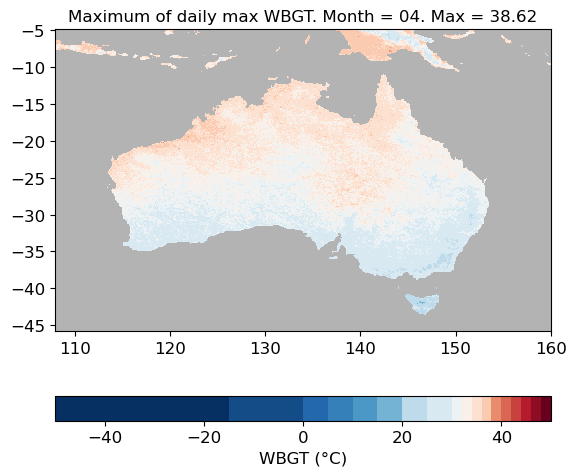

In [30]:
if daily_freq == 'max':
    make_plot(wbgt_max_2d_computed,'wbgt',discrete='yes',set_clims='equal')
    plt.title('Maximum of daily ' + daily_freq + ' WBGT. Month = ' + str(set_month) + '. Max = ' + str(np.round(np.nanmax(wbgt_max_2d_computed),2)))
elif daily_freq == 'min':
    make_plot(wbgt_min_2d_computed,'wbgt',discrete='yes',set_clims='equal')
    plt.title('Minimum of daily ' + daily_freq + ' WBGT. Month = ' + str(set_month) + '. Min = ' + str(np.round(np.nanmin(wbgt_min_2d_computed),2)))

plt.pcolor(laf_ds['lon'], laf_ds['lat'], ocean_regions_50pc, cmap='Set2_r', zorder=2)


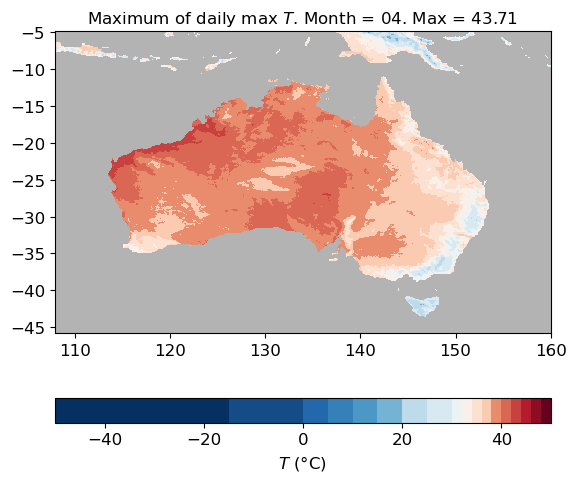

In [31]:
if daily_freq == 'max':
    make_plot(t_max_2d_computed,'t',discrete='yes',set_clims='equal')
    plt.title('Maximum of daily ' + daily_freq + ' $\it{T}$. Month = ' + str(set_month) + '. Max = ' + str(np.round(np.nanmax(t_max_2d_computed),2)))
elif daily_freq == 'min':
    make_plot(t_min_2d_computed,'t',discrete='yes',set_clims='equal')
    plt.title('Minimum of daily ' + daily_freq + ' $\it{T}$. Month = ' + str(set_month) + '. Min = ' + str(np.round(np.nanmin(t_min_2d_computed),2)))

plt.pcolor(laf_ds['lon'], laf_ds['lat'], ocean_regions_50pc, cmap='Set2_r', zorder=2)


In [32]:
def wbgt_t_max_limit(t,buffer=0):
    swbgt_t = 1.916 * 10**(-6) * (t**4) + 9.481 * 10**(-5) * (t**3) + 0.005353 * (t**2) - 0.2554 * t + 6.357 + buffer
    return swbgt_t
    
def wbgt_minus_t_above_limit_mask(t,wbgt_minus_t,buffer=0):

    # This function puts ones where value is above the threshold, NaNs where values are equal to or below
    
    wbgt_minus_t_mask = np.array(wbgt_minus_t.copy() * np.nan)

    swbgt_t_max_limit = np.array(1.916 * 10**(-6) * (t**4) + 9.481 * 10**(-5) * (t**3) + 0.005353 * (t**2) - 0.2554 * t + 6.357 + buffer)
    wbgt_minus_t_mask[np.where(np.array(wbgt_minus_t) > swbgt_t_max_limit)] = 1
    del swbgt_t_max_limit

    return wbgt_minus_t_mask # .data
    

In [33]:
# Identify where WBGT-T differences are abvoe the curve
# This array will have NaNs where value is within or below curve, and ones where value is above curve

above_curve_bin_t = wbgt_minus_t_above_limit_mask(np.array(t_computed),np.array(wbgt_t_diff_computed),buffer=0)


In [34]:
# Count values above curve for each lat-lon point
above_curve_bin_t_sum = np.nansum(above_curve_bin_t,axis=0)

if apply_ocean_area_mask == 'yes':
    above_curve_bin_t_sum = above_curve_bin_t_sum * land_regions_50pc


In [35]:
dir_out = '/home/565/cdr565/heat/figures/treasury/'
fname_out_common = '_month-' + set_month + '_daily-' + daily_freq

if apply_ocean_area_mask == 'yes':
    fname_out_common += '_mask-ocean'
if crop_to_aust_region == 'yes':
    fname_out_common += '_crop-aust'

print(fname_out_common)

_month-04_daily-max_mask-ocean_crop-aust


In [36]:
lats_array = np.ones(np.shape(above_curve_bin_t_sum)) * np.nan
lons_array = np.ones(np.shape(above_curve_bin_t_sum)) * np.nan

[num_lats, num_lons] = np.shape(above_curve_bin_t_sum)
for i in np.arange(num_lons):
    lats_array[:,i] = wbgt_computed.latitude.data
for i in np.arange(num_lats):
    lons_array[i,:] = wbgt_computed.longitude.data
    

In [37]:
# Mask out land north of Australia - Indonesia, PNG
aust_mask = land_regions_50pc.copy()
aust_mask[np.where(lats_array > -9.5)] = np.nan
aust_mask[np.where((lats_array > -15) * (lons_array > 147))] = np.nan
aust_mask[np.where((lats_array > -12) * (lons_array < 130))] = np.nan


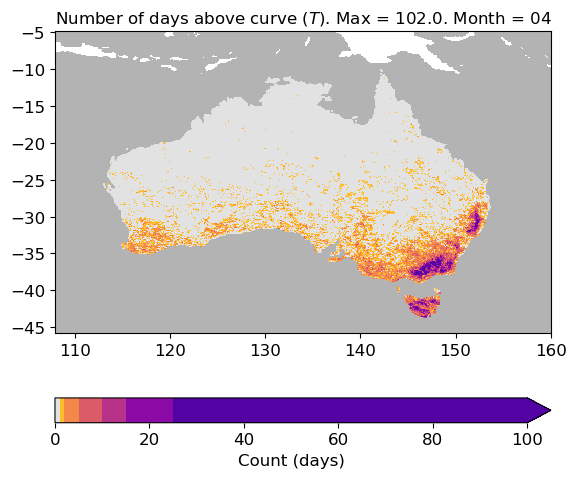

In [38]:
make_plot(above_curve_bin_t_sum*aust_mask, var_type='count', lons=laf_ds['lon'], lats=laf_ds['lat'])

plt.pcolor(laf_ds['lon'], laf_ds['lat'], ocean_regions_50pc, cmap='Set2_r', zorder=1)

plt.title('Number of days above curve ($\it{T}$). Max = ' + str(np.nanmax(above_curve_bin_t_sum*aust_mask)) + '. Month = ' + set_month)

fname_out = dir_out + 'wbgt_treasury_num_days_above_curve_t' + fname_out_common

plt.savefig(fname_out + '.png', bbox_inches='tight', pad_inches=0.2, dpi=600)


In [39]:
print()

print('Max number of cells affected per day = ' + str(np.nanmax(np.nansum(np.nansum(above_curve_bin_t,axis=1),axis=1))))
print('Mean number of cells affected per day = ' + str(np.round(np.nanmean(np.nansum(np.nansum(above_curve_bin_t,axis=1),axis=1)),2)))
print('Number of cells affected = ' + str(np.nansum(above_curve_bin_t_sum/above_curve_bin_t_sum)))

print()


Max number of cells affected per day = 406.0
Mean number of cells affected per day = 95.64
Number of cells affected = 14734.0



/jobfs/163368897.gadi-pbs/ipykernel_2660321/219264847.py:5: RuntimeWarning: invalid value encountered in divide
  print('Number of cells affected = ' + str(np.nansum(above_curve_bin_t_sum/above_curve_bin_t_sum)))


In [40]:
# Calculate distance of WBGT-T value above upper limit
dist_above_curve_t = (wbgt_t_diff_computed.data - wbgt_t_max_limit(t_computed,buffer=0)) # * above_curve_bin_t


/jobfs/163368897.gadi-pbs/ipykernel_2660321/3361983906.py:1: RuntimeWarning: All-NaN axis encountered
  make_plot(np.nanmax(dist_above_curve_t*aust_mask,axis=0), var_type='diff10', lons=laf_ds['lon'], lats=laf_ds['lat'])
/jobfs/163368897.gadi-pbs/ipykernel_2660321/3361983906.py:5: RuntimeWarning: All-NaN axis encountered
  max_diff = np.nanmax(np.nanmax(dist_above_curve_t*aust_mask,axis=0))


Text(0.5, 1.0, 'Max dist. above $\\it{T}$ curve (max = 6.44)')

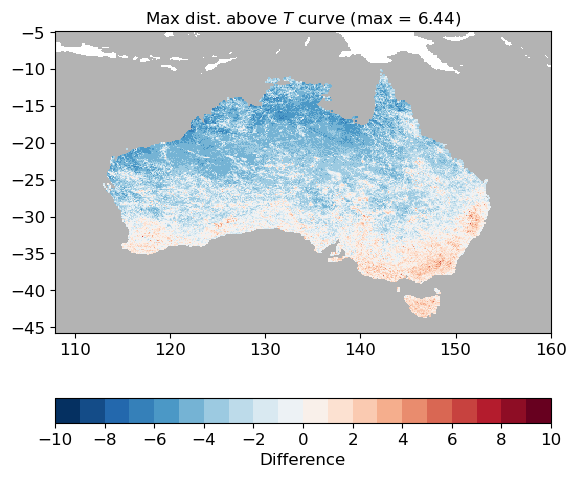

In [41]:

make_plot(np.nanmax(dist_above_curve_t*aust_mask,axis=0), var_type='diff10', lons=laf_ds['lon'], lats=laf_ds['lat'])

plt.pcolor(laf_ds['lon'], laf_ds['lat'], ocean_regions_50pc, cmap='Set2_r', zorder=1)

max_diff = np.nanmax(np.nanmax(dist_above_curve_t*aust_mask,axis=0))

plt.title('Max dist. above $\it{T}$ curve (max = ' + str(np.round(max_diff,2)) + ')')


In [42]:
# Create temperature array for scatterplot
xp1 = np.linspace(-20.0, 50.0, 100)



Code run time: 19.81 minutes


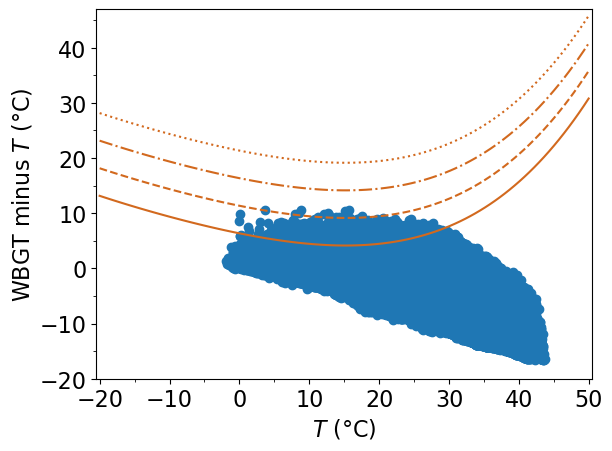

In [43]:
# Create scatterplot for T (x-axis) vs. WBGT minus T (y-axis) for daily data. This takes over 30 mins to plot.

import time as time_pack
start_timer = time_pack.perf_counter()

set_fontsize = 16
plt.rcParams.update({'font.size': 10,
                    'axes.labelsize':set_fontsize, # Axes labels
                    'xtick.labelsize':set_fontsize,
                    'ytick.labelsize':set_fontsize})

ax1 = plt.subplot(111)

if crop_to_aust_region == 'yes':
    plt.scatter(t_computed,wbgt_t_diff_computed * aust_mask)
else:
    plt.scatter(t_computed,wbgt_t_diff_computed)

# Add max T curve here
plt.plot(xp1, wbgt_t_max_limit(xp1,buffer=0),c='chocolate',linestyle='-')

plt.plot(xp1, wbgt_t_max_limit(xp1,buffer=5),c='chocolate',linestyle='--')

plt.plot(xp1, wbgt_t_max_limit(xp1,buffer=10),c='chocolate',linestyle='-.')

plt.plot(xp1, wbgt_t_max_limit(xp1,buffer=15),c='chocolate',linestyle=':')

plt.xlabel('$\it{T}$ (\N{degree sign}C)')
plt.ylabel('WBGT minus $\it{T}$ (\N{degree sign}C)')

x_min = -20.5
x_max = 50.5
y_min = -20
y_max = 47

x_max = np.nanmax([x_max,np.nanmax(t_computed)])
x_min = np.nanmin([x_min,np.nanmin(t_computed)])
y_max = np.nanmax([y_max,np.nanmax(wbgt_t_diff_computed)])
y_min = np.nanmin([y_min,np.nanmin(wbgt_t_diff_computed)])

plt.xlim([x_min,x_max])
plt.ylim([y_min,y_max])

ax1.xaxis.set_major_locator(MultipleLocator(10)) # Major ticks
ax1.xaxis.set_minor_locator(MultipleLocator(5)) # Minor ticks
ax1.yaxis.set_major_locator(MultipleLocator(10)) # Major ticks
ax1.yaxis.set_minor_locator(MultipleLocator(5)) # Minor ticks

fname_out = dir_out + 'T_vs_WBGTminusT' + fname_out_common
plt.savefig(fname_out + '.png', bbox_inches='tight', pad_inches=0.2, dpi=600)

print_run_time(start_timer)


In [44]:
# Create arrays with top 10 magnitude values 
# Output these later and use in other plotting script

try: del i
except: pass
try: del j
except: pass

above_curve_dist_t = np.nanmax(wbgt_t_diff_computed - wbgt_t_max_limit(np.array(t_computed),buffer=0),axis=0)
above_curve_dist_t_copy = above_curve_dist_t.copy()

top_10_lats_t_magnitude = np.zeros(10) * np.nan
top_10_lons_t_magnitude = np.zeros(10) * np.nan
top_10_value_t_magnitude = np.zeros(10) * np.nan

for i in np.arange(10):
    top_10_lats_t_magnitude[i] = wbgt_t_diff_computed.latitude[np.where(above_curve_dist_t_copy == np.nanmax(above_curve_dist_t_copy*aust_mask))[0][0]].data
    top_10_lons_t_magnitude[i] = wbgt_t_diff_computed.longitude[np.where(above_curve_dist_t_copy == np.nanmax(above_curve_dist_t_copy*aust_mask))[1][0]].data
    top_10_value_t_magnitude[i] = np.nanmax(above_curve_dist_t_copy)

    distance_array = ((lats_array - top_10_lats_t_magnitude[i]) ** 2 + (lons_array - top_10_lons_t_magnitude[i]) ** 2) ** (1/2)
    above_curve_dist_t_copy[np.where(distance_array < 5)] = np.nan


text_fname_out = 'top10-magnitude-t_' + set_month

text_file_name = text_fname_out + '.txt'

text_file = open(dir_out + text_file_name, "w")

for i in np.arange(10):
    text_line = str(top_10_lats_t_magnitude[i]) + ',' + str(top_10_lons_t_magnitude[i]) + ',' + str(top_10_value_t_magnitude[i]) + '\n'
    text_file.write(text_line)

text_file.close()


/jobfs/163368897.gadi-pbs/ipykernel_2660321/2029622877.py:9: RuntimeWarning: All-NaN axis encountered
  above_curve_dist_t = np.nanmax(wbgt_t_diff_computed - wbgt_t_max_limit(np.array(t_computed),buffer=0),axis=0)


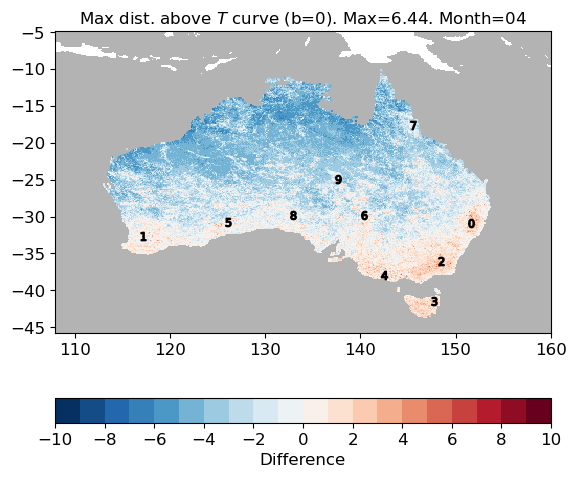

In [45]:

make_plot(above_curve_dist_t*aust_mask, var_type='diff10', lons=laf_ds['lon'], lats=laf_ds['lat'])

plt.title('Max dist. above $\it{T}$ curve (b=0). Max=' + str(np.round(np.nanmax(above_curve_dist_t*aust_mask),2)) + '. Month=' + set_month)

plt.pcolor(laf_ds['lon'], laf_ds['lat'], ocean_regions_50pc, cmap='Set2_r')

for i in np.arange(len(top_10_lats_t_magnitude)):
    plt.scatter(top_10_lons_t_magnitude[i],top_10_lats_t_magnitude[i],c='k',marker='$' + str(i) + '$',zorder=3)

fname_out = dir_out + 'wbgt_treasury_dist_above_curve_t' + fname_out_common + "_top10"

plt.savefig(fname_out + '.png', bbox_inches='tight', pad_inches=0.2, dpi=600)


In [46]:
lats_2d = np.ones(np.shape(wbgt_max_2d_computed.data)) * np.nan
for i in np.arange(len(wbgt_max_2d_computed[lon_name].data)):
    lats_2d[:,i] = wbgt_max_2d_computed[lat_name].data


In [47]:

if set_month == '11':
    lat_lat = -43.56
else:
    lat_lat = -43.56

lat_array_single = np.zeros(np.shape(wbgt_max_2d_computed[lon_name])[0]) + lat_lat
if daily_freq == 'max':
    wbgt_max_2d_computed_lat = wbgt_max_2d_computed.where(wbgt_max_2d_computed[lat_name] == lat_lat, drop=True)
elif daily_freq == 'min':
    wbgt_min_2d_computed_lat = wbgt_min_2d_computed.where(wbgt_min_2d_computed[lat_name] == lat_lat, drop=True)


In [48]:
max_max = wbgt_max_2d_computed.max().values
print('max of max = ' + str(np.round((max_max), 4)) + ' C')
min_min = wbgt_min_2d_computed.min().values
print('min of min = ' + str(np.round((min_min), 4)) + ' C')

max of max = 38.6239 C
min of min = -0.9554 C


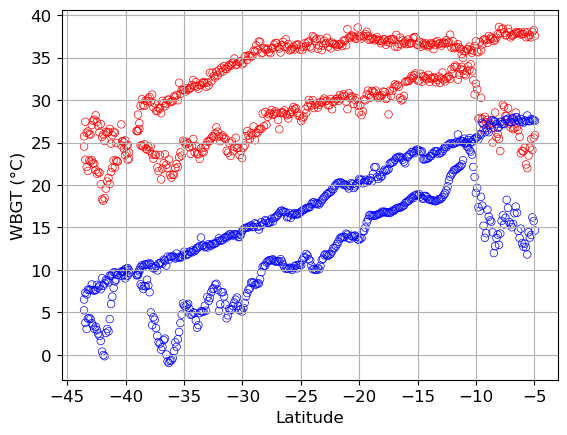

In [52]:
# Plot range of maximum and minimum WBGT values - use to inspect for any obvious outliers
make_scatter_max(wbgt_max_2d_computed,'wbgt')
make_scatter_min(wbgt_max_2d_computed,'wbgt')
make_scatter_max(wbgt_min_2d_computed,'wbgt',colour='b')
make_scatter_min(wbgt_min_2d_computed,'wbgt',colour='b')

fname_out = dir_out + 'wbgt_treasury_wbgt_by_lat' + fname_out_common

plt.savefig(fname_out + '.png', bbox_inches='tight', pad_inches=0.2, dpi=600)

In [53]:
# Determine the number of standard deviations for each wbgt value
wbgt_anomaly = wbgt_computed - wbgt_mean_2d_computed
wbgt_num_stds = wbgt_anomaly / wbgt_std_2d_computed
wbgt_num_stds_abs = abs(wbgt_num_stds)


In [54]:
t_mean_2d = t_computed.mean(dim='time')
t_std_2d_computed = t_computed.std(dim='time')

In [55]:
# Determine the number of standard deviations for each Tw value
t_anomaly = t_computed - t_mean_2d
t_num_stds = t_anomaly / t_std_2d_computed

t_num_stds_max_2d = t_num_stds.max(dim='time')


In [56]:
# Find maximum standard deviation (abs)
start_timer = time_pack.perf_counter()

wbgt_num_stds_abs_max_2d = wbgt_num_stds_abs.max(dim='time')

print_run_time(start_timer)



Code run time: 0.01 minutes


In [57]:
wbgt_num_stds_gr5 = np.array(wbgt_num_stds.copy())
wbgt_num_stds_gr5[np.where(wbgt_num_stds_gr5 <= 5.)] = np.nan


In [58]:
# Find maximum standard deviation
start_timer = time_pack.perf_counter()

wbgt_num_stds_max_2d = wbgt_num_stds.max(dim='time')

print_run_time(start_timer)



Code run time: 0.01 minutes


In [59]:
# Find minimum standard deviation
start_timer = time_pack.perf_counter()

wbgt_num_stds_min_2d = wbgt_num_stds.min(dim='time')

print_run_time(start_timer)



Code run time: 0.01 minutes


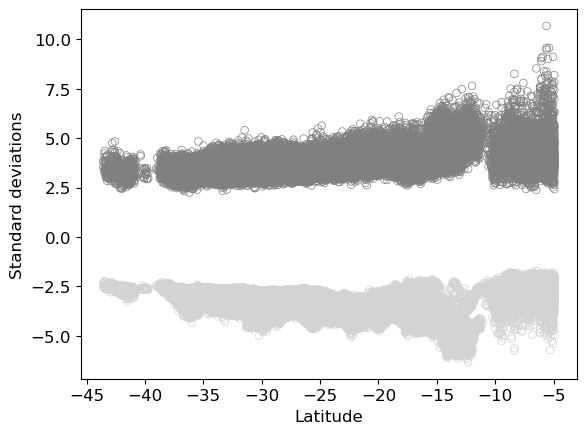

In [60]:
# Max and min standard deviation for each lat-lon point, plotted by latitude
plt.scatter(lats_2d, wbgt_num_stds_max_2d, s=30, facecolors='none', edgecolors='grey', linewidths=0.5)
plt.scatter(lats_2d, wbgt_num_stds_min_2d, s=30, facecolors='none', edgecolors='lightgrey', linewidths=0.5)

plt.xlabel('Latitude')
plt.ylabel('Standard deviations')

fname_out = dir_out + 'wbgt_treasury_stdev_by_lat' + fname_out_common

plt.savefig(fname_out + '.png', bbox_inches='tight', pad_inches=0.2, dpi=600)


04


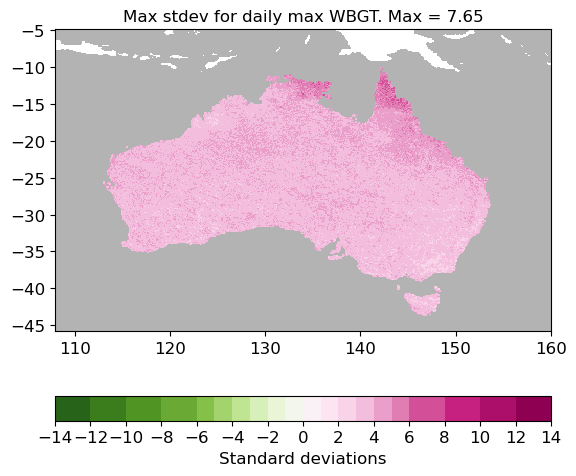

In [61]:
if daily_freq == 'max':
    make_plot(wbgt_num_stds_max_2d*aust_mask,'std')
    plt.pcolor(wbgt_num_stds_max_2d['longitude'], wbgt_num_stds_max_2d['latitude'], ocean_regions_50pc, cmap='Set2_r') # 'Set2_r'
    plt.title('Max stdev for daily max WBGT. Max = ' + str(np.round(np.nanmax(wbgt_num_stds_max_2d*aust_mask),2)))
elif daily_freq == 'min':
    make_plot(wbgt_num_stds_min_2d*aust_mask,'std')
    plt.pcolor(wbgt_num_stds_max_2d['longitude'], wbgt_num_stds_max_2d['latitude'], ocean_regions_50pc, cmap='Set2_r') # 'Set2_r'
    plt.title('Min stdev for daily min WBGT. Min = ' + str(np.round(np.nanmin(wbgt_num_stds_min_2d*aust_mask),2)))
print(set_month)


In [62]:
try: del i
except: pass
try: del j
except: pass

top_10_lats_stds_magnitude = np.zeros(10) * np.nan
top_10_lons_stds_magnitude = np.zeros(10) * np.nan
top_10_value_stds_magnitude = np.zeros(10) * np.nan

if daily_freq == 'max':
    stds_magnitude = wbgt_num_stds_max_2d
elif daily_freq == 'min':
    stds_magnitude = wbgt_num_stds_min_2d

stds_magnitude_copy = stds_magnitude.copy()

for i in np.arange(10):
    top_10_lats_stds_magnitude[i] = wbgt_num_stds_max_2d.latitude[np.where(stds_magnitude_copy == np.nanmax(stds_magnitude_copy*aust_mask))[0][0]].data
    top_10_lons_stds_magnitude[i] = wbgt_num_stds_max_2d.longitude[np.where(stds_magnitude_copy == np.nanmax(stds_magnitude_copy*aust_mask))[1][0]].data
    top_10_value_stds_magnitude[i] = stds_magnitude.data[np.where(stds_magnitude_copy == np.nanmax(stds_magnitude_copy*aust_mask))][0]

    distance_array = ((lats_array - top_10_lats_stds_magnitude[i]) ** 2 + (lons_array - top_10_lons_stds_magnitude[i]) ** 2) ** (1/2)
    stds_magnitude_copy[np.where(distance_array < 5)] = np.nan


text_fname_out = 'top10_stds-magnitude_' + set_month

text_file_name = text_fname_out + '.txt'

text_file = open(dir_out + text_file_name, "w")

for i in np.arange(10):
    text_line = str(top_10_lats_stds_magnitude[i]) + ',' + str(top_10_lons_stds_magnitude[i]) + ',' + str(top_10_value_stds_magnitude[i]) + '\n'
    text_file.write(text_line)

text_file.close()


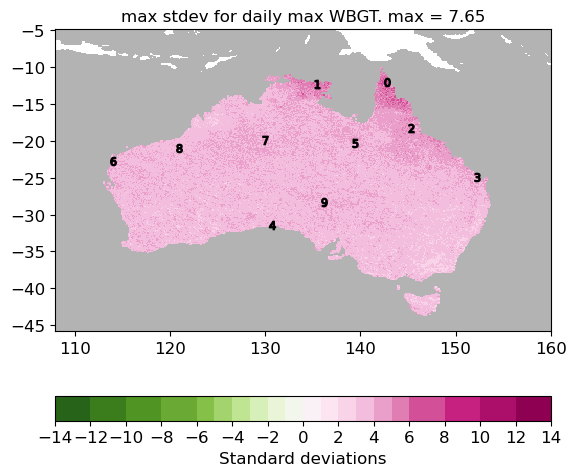

In [63]:
# top10

make_plot(stds_magnitude*aust_mask, var_type='std', lons=laf_ds['lon'], lats=laf_ds['lat'])

plt.pcolor(wbgt_num_stds_max_2d['longitude'], wbgt_num_stds_max_2d['latitude'], ocean_regions_50pc, cmap='Set2_r') # 'Set2_r'

for i in np.arange(len(top_10_lats_stds_magnitude)):
    plt.scatter(top_10_lons_stds_magnitude[i],top_10_lats_stds_magnitude[i],c='k',marker='$' + str(i) + '$',zorder=3)

if daily_freq == 'max':
    plt.title(daily_freq + ' stdev for daily ' + daily_freq + ' WBGT. ' + daily_freq + ' = ' + str(np.round(np.nanmax(stds_magnitude*aust_mask),2)))
elif daily_freq == 'min':
    plt.title(daily_freq + ' stdev for daily ' + daily_freq + ' WBGT. ' + daily_freq + ' = ' + str(np.round(np.nanmin(stds_magnitude*aust_mask),2)))

fname_out = dir_out + 'wbgt_treasury_' + daily_freq + '_stdev_wbgt_top10' + fname_out_common

plt.savefig(fname_out + '.png', bbox_inches='tight', pad_inches=0.2, dpi=600)


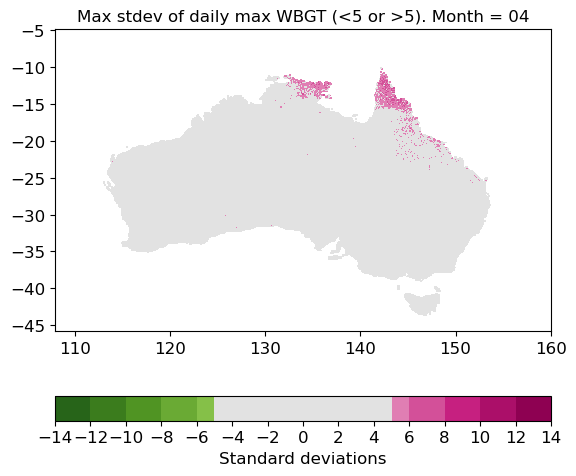

In [64]:
if daily_freq == 'max':
    make_plot(wbgt_num_stds_max_2d*aust_mask,'std_5plus',lats=wbgt_num_stds_max_2d['latitude'],lons=wbgt_num_stds_max_2d['longitude'])
    plt.title('Max stdev of daily max WBGT (<5 or >5). Month = ' + str(set_month))

elif daily_freq == 'min':
    make_plot(wbgt_num_stds_min_2d*aust_mask,'std_5plus',lats=wbgt_num_stds_max_2d['latitude'],lons=wbgt_num_stds_max_2d['longitude'])
    plt.title('Min stdev of daily min WBGT (<5 or >5). Month = ' + str(set_month))

# fname_out = dir_out + 'wbgt_treasury_' + daily_freq + '_stdev_wbgt_gre5' + fname_out_common
# plt.savefig(fname_out + '.png', bbox_inches='tight', pad_inches=0.2, dpi=600)


In [65]:
wbgt_num_stds_gr5_bin = wbgt_num_stds_gr5.copy() * aust_mask
wbgt_num_stds_gr5_bin[np.where(~np.isnan(wbgt_num_stds_gr5))] = 1.0

wbgt_num_stds_gr5_count = np.nansum(wbgt_num_stds_gr5_bin,axis=0)
wbgt_num_stds_gr5_count = wbgt_num_stds_gr5_count * land_regions_50pc * aust_mask


Text(0.5, 1.0, 'Count stdev(daily max WBGT) > 5. Month = 04. Max = 7.0')

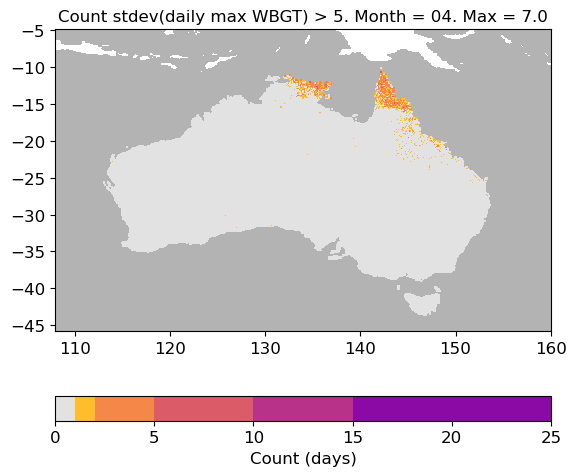

In [66]:
# Plot the number of days where the standard deviation is greater than 5
# Note that non-Australian regions show counts of zero as these regions were not included in the analysis

make_plot(wbgt_num_stds_gr5_count, var_type='count', lons=laf_ds['lon'], lats=laf_ds['lat']) # count (days)
plt.pcolor(wbgt_num_stds_max_2d['longitude'], wbgt_num_stds_max_2d['latitude'], ocean_regions_50pc, cmap='Set2_r') # 'Set2_r'
plt.title('Count stdev(daily max WBGT) > 5. Month = ' + str(set_month) + '. Max = ' + str(np.nanmax(wbgt_num_stds_gr5_count*aust_mask)))

# fname_out = dir_out + 'wbgt_treasury_' + daily_freq + 'count' + '_stdev_wbgt_gre5' + fname_out_common
# plt.savefig(fname_out + '.png', bbox_inches='tight', pad_inches=0.2, dpi=600)


In [67]:
try: del i
except: pass
try: del j
except: pass

top_10_lats_stds = np.zeros(10) * np.nan
top_10_lons_stds = np.zeros(10) * np.nan
top_10_value_stds_count = np.zeros(10) * np.nan
top_10_value_stds = np.zeros(10) * np.nan

wbgt_num_stds_gr5_count_copy = wbgt_num_stds_gr5_count.copy()

# Mask out values north of -10.5
wbgt_num_stds_gr5_count_copy[np.where(lats_array > -10.5)] = np.nan

for i in np.arange(10):
    top_10_lats_stds[i] = wbgt_num_stds_max_2d.latitude[np.where(wbgt_num_stds_gr5_count_copy == np.nanmax(wbgt_num_stds_gr5_count_copy))[0][0]].data
    top_10_lons_stds[i] = wbgt_num_stds_max_2d.longitude[np.where(wbgt_num_stds_gr5_count_copy == np.nanmax(wbgt_num_stds_gr5_count_copy))[1][0]].data
    top_10_value_stds_count[i] = np.nanmax(wbgt_num_stds_gr5_count_copy)
    top_10_value_stds[i] = wbgt_num_stds_max_2d.data[np.where(wbgt_num_stds_gr5_count_copy == np.nanmax(wbgt_num_stds_gr5_count_copy))][0]

    distance_array = ((lats_array - top_10_lats_stds[i]) ** 2 + (lons_array - top_10_lons_stds[i]) ** 2) ** (1/2)
    wbgt_num_stds_gr5_count_copy[np.where(distance_array < 5)] = np.nan


In [68]:
text_fname_out = 'top10_stds_' + set_month

text_file_name = text_fname_out + '.txt'

text_file = open(dir_out + text_file_name, "w")

for i in np.arange(10):
    text_line = str(top_10_lats_stds[i]) + ',' + str(top_10_lons_stds[i]) + ',' + str(top_10_value_stds_count[i]) + ',' + str(top_10_value_stds[i]) + '\n'
    text_file.write(text_line)

text_file.close()


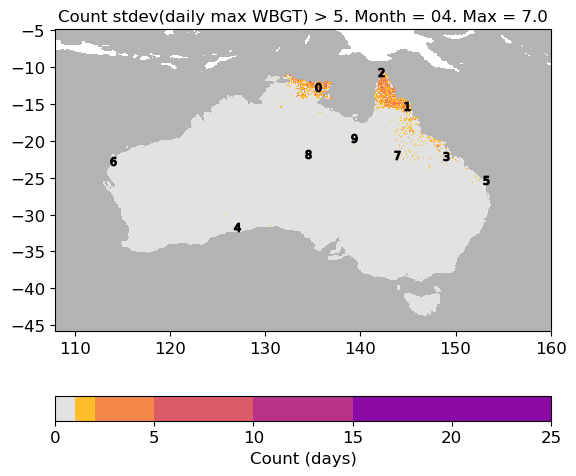

In [69]:
# top10

# Plot the number of days where the standard deviation is greater than 5
# Note that non-Australian regions show counts of zero as these regions were not included in the analysis

make_plot(wbgt_num_stds_gr5_count, var_type='count', lons=laf_ds['lon'], lats=laf_ds['lat'])

plt.pcolor(wbgt_num_stds_max_2d['longitude'], wbgt_num_stds_max_2d['latitude'], ocean_regions_50pc, cmap='Set2_r') # 'Set2_r'

plt.title('Count stdev(daily max WBGT) > 5. Month = ' + str(set_month) + '. Max = ' + str(np.nanmax(wbgt_num_stds_gr5_count*aust_mask)))

for i in np.arange(len(top_10_lats_stds)):
    plt.scatter(top_10_lons_stds[i],top_10_lats_stds[i],c='k',marker='$' + str(i) + '$',zorder=3)

fname_out = dir_out + 'wbgt_treasury_' + daily_freq + '_count' + '_stdev_wbgt_gre5_top10' + fname_out_common

plt.savefig(fname_out + '.png', bbox_inches='tight', pad_inches=0.2, dpi=600)


Text(0.5, 1.0, 'Min stdev of daily max WBGT. Month = 04. Min = -6.32')

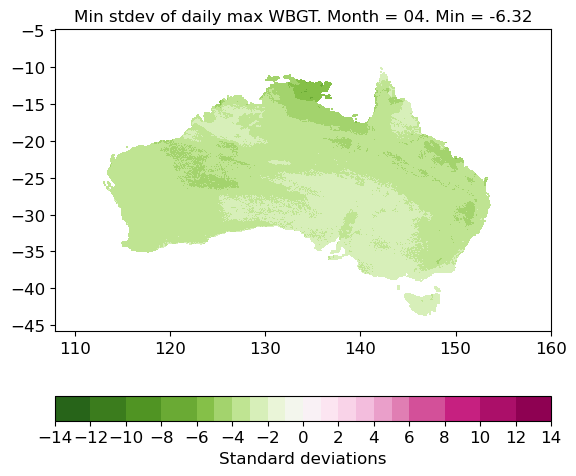

In [70]:
make_plot(wbgt_num_stds_min_2d*aust_mask,'std',lats=wbgt_num_stds_min_2d['latitude'],lons=wbgt_num_stds_min_2d['longitude'])
plt.title('Min stdev of daily ' + daily_freq + ' WBGT. Month = ' + str(set_month) + '. Min = ' + str(np.round(np.nanmin(wbgt_num_stds_min_2d*aust_mask),2)))


Text(0.5, 1.0, 'Max stdev of daily max $\\it{T}$. Month = 04. Max = 6.52')

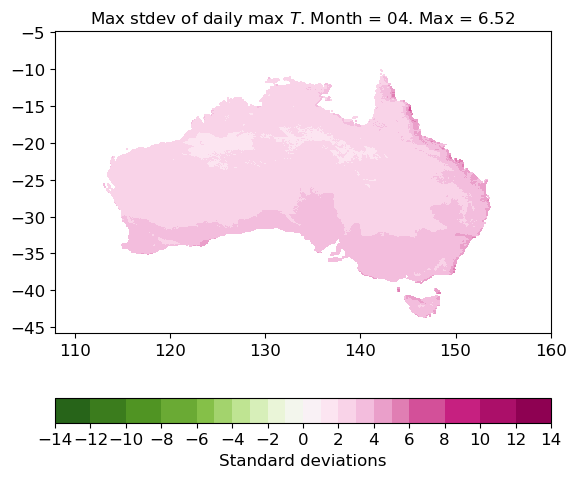

In [71]:

make_plot(t_num_stds_max_2d*aust_mask,'std',lats=t_num_stds_max_2d['lat'],lons=t_num_stds_max_2d['lon'])
plt.title('Max stdev of daily ' + daily_freq + ' $\it{T}$. Month = ' + str(set_month) + '. Max = ' + str(np.round(np.nanmax(t_num_stds_max_2d*aust_mask),2)))
